In [1]:
import os
import pandas as pd
import scanpy as sc
from itertools import chain
import matplotlib.pyplot as plt
from matplotlib.path import Path

In [ ]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'invertebrate', 'holigactis')
# pth_out = os.path.join(pth_data, 'results', 'cancer', 'holigactis')
pth_fig = os.path.join(pth, 'figures', 'invertebrate', 'holigactis')
pth_cb = os.path.join(pth_fig, 'colorbars')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'tumor.h5ad'))
adata.obs['sample'] = adata.obs_names.astype('category')
adata

AnnData object with n_obs × n_vars = 4 × 9971
    obs: 'sample'
    layers: 'gProcessedSignal'

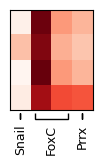

In [5]:
# source: NCBI names (H. vulgaris) + BLAST (Hydra Genome Project)
g_plt = {
    'Snail' : ['HOLI00251.G8870'],
    'FoxC'  : ['HOLI11838.G1764', 'HOLI00925.G36738'],
    'Prrx'  : ['HOLI07521.G24635']}

# expression heatmap
ncol = len(list(chain(*g_plt.values())))
fs, figsize = 9, (1.5 * (ncol / adata.n_obs), 1.5)
hm = sc.pl.heatmap(adata, g_plt, 'sample',
                   cmap = 'Reds',
                   figsize = figsize,
                   show_gene_labels = False,
                   show = False)

ax_hm = hm['heatmap_ax']
ax_grp = hm['groupby_ax']
ax_var = hm['gene_groups_ax']
ax_cb = ax_hm.figure.axes[1]
ax_cb.set_visible(False)
ax_grp.set_visible(False)

for ax in (ax_hm, ax_var):
    ax.invert_yaxis()

bracket = ax_var.patches[0]
bracket.set_linewidth(1)
path = bracket.get_path()
verts = path.vertices.copy()

for i, (key, val) in enumerate(g_plt.items()):
    if len(val) == 1:
        j = i * 4
        center = (verts[j, 0] + verts[j + 3, 0]) / 2
        verts[j] = (center, 0)
        verts[j + 1] = (center, .6)
        verts[j + 2] = (center, .6)
        verts[j + 3] = (center, 0)
bracket.set_path(Path(verts, path.codes))

for t in ax_var.texts:
    t.set_va('top')
    t.set_fontsize(fs)

for l in ax_hm.collections:
    l.remove()

pos_hm  = ax_hm.get_position()
pos_var = ax_var.get_position()
ax_var.set_position([pos_var.x0,
                     pos_hm.y0 - pos_var.height - .02,
                     pos_var.width,
                     pos_var.height])

fn = os.path.join(pth_fig, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight', dpi = 1200)

/home/caleb/tmp/ipykernel_3765203/3810024310.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 150x150 with 4 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax_cb.collections[1], cax = cax)


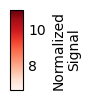

In [11]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .2, .8])
cb = plt.colorbar(ax_cb.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Normalized\nSignal')
cb.set_ticks([8, 10])
fn = os.path.join(pth_cb, 'expression_cb.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [ ]:
# # save results
# df = pd.concat({
#       name : pd.DataFrame(adata[:, g].X, columns = g,
#                           index = adata.obs_names)
#       for name, g in g_plt.items()}, axis = 1).T
# df.to_csv(os.path.join(pth_out, 'expression.csv'))